# KernelSHAP on SAM Partitions

This notebook is a small sanity check for adding **KernelSHAP over SAM regions** beside the current ShapBPT flow.

It compares:

1. **ShapBPT** built directly from the image.
2. **ShapBPT + SAM partition** using `prebuilt_partitions`.
3. **KernelSHAP + SAM partition** where each SAM region is one interpretable feature.


In [13]:
from pathlib import Path
import sys
import time
from math import comb

import numpy as np
import pandas as pd
import torch
import shap_bpt
from ultralytics import YOLO

# Find project root from the notebook location/current working directory.
PROJECT_ROOT = Path.cwd().resolve()
for candidate in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (candidate / "shap_bpt").is_dir() and (candidate / "examples" / "scripts").is_dir():
        PROJECT_ROOT = candidate
        break

SCRIPTS_DIR = PROJECT_ROOT / "examples" / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from run_yolo_full import (
    load_image_to_explain,
    make_predict_yolo_masked,
    resolve_yolo_source,
    select_device,
    yolo_class_count,
)
from utils_sam_2 import load_refine_partitions
import utils_xai as utx

# run_yolo_full.py uses the Agg backend for script execution. Switch back for notebooks.
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass
import matplotlib.pyplot as plt

print("Project root:", PROJECT_ROOT)


Project root: /Users/rashid/Nextcloud/RashidPHD/Codes/XAI/ShapBPT-SAM/shap_bpt_sam


In [6]:
# -------------------------
# User settings
# -------------------------
IMAGE_ID = "000000000785"
YOLO_MODEL = "yolo11s"
DEVICE_NAME = "auto"  # auto, cuda, mps, cpu
BG_TYPE = "noise"     # black, gray, white, blurred, noise, full
CLASS_AGGREGATION = "sum"

MAX_EVALS_BPT = 500
BPT_BATCH_SIZE = 256

# KernelSHAP samples are coalitions over SAM regions, not image pixels.
KERNEL_SHAP_SAMPLES = 512
KERNEL_SHAP_BATCH_SIZE = 128
KERNEL_SHAP_SEED = 0

IMAGE_DIR = Path("/Users/rashid/data/DS/MS_COCO/val2017")
MASKS_BASE_PATH = Path(
    "/Users/rashid/data/PhD/datacloud_data/repos/XAI/ShapBPT-SAM/"
    "shap_bpt_sam/examples/data/risultati_120/120_refined_filled"
)
CHECKPOINT_DIR =  "/Users/rashid/Nextcloud/RashidPHD/Codes/XAI/ShapBPT-SAM/Shap_BPT_SAM_tests/src/checkpoints/" #PROJECT_ROOT / "examples" / "notebooks" / "checkpoints"

device = select_device(DEVICE_NAME)
print("Device:", device)
print("Image dir exists:", IMAGE_DIR.exists(), IMAGE_DIR)
print("Masks dir exists:", MASKS_BASE_PATH.exists(), MASKS_BASE_PATH)


Device: mps
Image dir exists: True /Users/rashid/data/DS/MS_COCO/val2017
Masks dir exists: True /Users/rashid/data/PhD/datacloud_data/repos/XAI/ShapBPT-SAM/shap_bpt_sam/examples/data/risultati_120/120_refined_filled


In [7]:
# Load model, image, background, and SAM partition.
yolo_source = resolve_yolo_source(PROJECT_ROOT, YOLO_MODEL, checkpoint_dir=str(CHECKPOINT_DIR))
model = YOLO(yolo_source)
class_names = model.names

input_data = load_image_to_explain(
    IMAGE_ID,
    str(IMAGE_DIR),
    model,
    class_names,
    device,
    bg_type=BG_TYPE,
    aggregate=CLASS_AGGREGATION,
)

image_to_explain = input_data["image_to_explain"]
background_image_set = input_data["background_image_set"]
predicted_cls = input_data["predicted_cls"]
fixed_category = input_data["fixed_category"]
f_S = input_data["f_S"]
f_0 = input_data["f_0"]

partitions_sam, partition_capped_sam = load_refine_partitions(
    image_to_explain,
    str(MASKS_BASE_PATH),
    IMAGE_ID,
    partition_type="sam",
    verbose=True,
)

predict_yolo_masked = make_predict_yolo_masked(
    model,
    image_to_explain,
    background_image_set,
    aggregate=CLASS_AGGREGATION,
)

top_k = [
    (int(cls), class_names[int(cls)], float(prob))
    for cls, prob in zip(input_data["sorted_classes"][:5], input_data["sorted_probs"][:5])
]
print("Image shape:", image_to_explain.shape)
print("SAM labels before cap:", len(np.unique(partitions_sam)))
print("SAM labels after cap:", len(np.unique(partition_capped_sam)))
print("Explained class:", predicted_cls, fixed_category, "f_S=", f_S, "f_0=", f_0)
print("Top-k:", top_k)


Loading partitions for image_id: 000000000785, partition_type: sam
Image shape: (425, 640, 3)
SAM labels before cap: 85
SAM labels after cap: 63
Explained class: 0 person f_S= 0.9396345615386963 f_0= 0.0
Top-k: [(0, 'person', 0.9396345615386963), (30, 'skis', 0.6040917634963989), (28, 'suitcase', 0.0), (21, 'bear', 0.0), (22, 'zebra', 0.0)]


In [8]:
def _kernel_shap_subset_weight(subset_size, n_features):
    if subset_size == 0 or subset_size == n_features:
        return 1e6
    return (n_features - 1) / (comb(n_features, subset_size) * subset_size * (n_features - subset_size))


def sample_kernel_shap_coalitions(n_features, n_samples=512, seed=0):
    """Sample binary coalitions for KernelSHAP in region-feature space."""
    rng = np.random.default_rng(seed)
    rows = [np.zeros(n_features, dtype=np.uint8), np.ones(n_features, dtype=np.uint8)]

    # Add singleton and leave-one-out coalitions; these stabilize small examples a lot.
    for i in range(n_features):
        z = np.zeros(n_features, dtype=np.uint8)
        z[i] = 1
        rows.append(z)

        z = np.ones(n_features, dtype=np.uint8)
        z[i] = 0
        rows.append(z)

    sizes = np.arange(1, n_features)
    size_probs = np.array([(n_features - 1) / (s * (n_features - s)) for s in sizes], dtype=float)
    size_probs = size_probs / size_probs.sum()

    seen = {row.tobytes() for row in rows}
    max_attempts = max(5000, n_samples * 20)
    attempts = 0
    while len(rows) < n_samples and attempts < max_attempts:
        attempts += 1
        s = int(rng.choice(sizes, p=size_probs))
        active = rng.choice(n_features, size=s, replace=False)
        z = np.zeros(n_features, dtype=np.uint8)
        z[active] = 1
        key = z.tobytes()
        if key not in seen:
            rows.append(z)
            seen.add(key)

    return np.stack(rows, axis=0)


def coalitions_to_region_masks(coalitions, partition, labels):
    masks = np.zeros((len(coalitions), *partition.shape), dtype=bool)
    for row_idx, z in enumerate(coalitions):
        active_labels = labels[z.astype(bool)]
        if len(active_labels):
            masks[row_idx] = np.isin(partition, active_labels)
    return masks


def kernel_shap_sam_regions(
    predict_masked,
    partition,
    target_cls,
    n_samples=512,
    batch_size=128,
    seed=0,
):
    """Compute KernelSHAP values where each SAM label is one feature."""
    partition = np.asarray(partition)
    labels = np.array(sorted(np.unique(partition)))
    n_features = len(labels)
    if n_features < 2:
        raise ValueError(f"KernelSHAP needs at least 2 regions, got {n_features}.")

    coalitions = sample_kernel_shap_coalitions(n_features, n_samples=n_samples, seed=seed)
    weights = np.array([_kernel_shap_subset_weight(int(z.sum()), n_features) for z in coalitions], dtype=float)

    y_values = []
    for start in range(0, len(coalitions), batch_size):
        z_batch = coalitions[start:start + batch_size]
        mask_batch = coalitions_to_region_masks(z_batch, partition, labels)
        preds = predict_masked(mask_batch)
        y_values.append(preds[:, target_cls])
    y_values = np.concatenate(y_values, axis=0).astype(float)

    X = np.column_stack([np.ones(len(coalitions)), coalitions.astype(float)])
    sqrt_w = np.sqrt(weights)
    beta, *_ = np.linalg.lstsq(X * sqrt_w[:, None], y_values * sqrt_w, rcond=None)

    base_value = float(beta[0])
    phi = beta[1:]
    heatmap = np.zeros(partition.shape, dtype=float)
    for label, value in zip(labels, phi):
        heatmap[partition == label] = value

    summary = pd.DataFrame({
        "label": labels,
        "kernel_shap_value": phi,
        "pixels": [int(np.sum(partition == label)) for label in labels],
    }).sort_values("kernel_shap_value", ascending=False)

    return heatmap[None, ...], {
        "labels": labels,
        "coalitions": coalitions,
        "weights": weights,
        "scores": y_values,
        "base_value": base_value,
        "sum_phi": float(phi.sum()),
        "full_minus_empty": float(y_values[1] - y_values[0]),
        "summary": summary,
    }


In [9]:
# ShapBPT on the image, ShapBPT with SAM partitions, and KernelSHAP on SAM partitions.
timings = {}
explainer = shap_bpt.Explainer(
    predict_yolo_masked,
    image_to_explain,
    explained_class_ids=[predicted_cls],
    verbose=True,
)

t0 = time.perf_counter()
bpt_image = shap_bpt.build_bpt_from_image(image_to_explain)
shap_values_bpt_image = explainer.explain_instance(
    MAX_EVALS_BPT,
    method="BPT",
    bpt=bpt_image,
    batch_size=BPT_BATCH_SIZE,
)
timings["ShapBPT image"] = time.perf_counter() - t0

t0 = time.perf_counter()
bpt_sam = shap_bpt.build_bpt_from_image(image_to_explain, 
                                        prebuilt_partitions=partition_capped_sam)
shap_values_bpt_sam = explainer.explain_instance(
    MAX_EVALS_BPT,
    method="BPT",
    bpt=bpt_sam,
    batch_size=BPT_BATCH_SIZE,
)
timings["ShapBPT SAM"] = time.perf_counter() - t0

t0 = time.perf_counter()
shap_values_kernel_sam, kernel_info = kernel_shap_sam_regions(
    predict_yolo_masked,
    partition_capped_sam,
    predicted_cls,
    n_samples=KERNEL_SHAP_SAMPLES,
    batch_size=KERNEL_SHAP_BATCH_SIZE,
    seed=KERNEL_SHAP_SEED,
)
timings["KernelSHAP SAM"] = time.perf_counter() - t0

pd.DataFrame([{"method": k, "seconds": v} for k, v in timings.items()])


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

,method,seconds
0,ShapBPT image,57.447457
1,ShapBPT SAM,55.068238
2,KernelSHAP SAM,51.973001


In [10]:
print("KernelSHAP checks")
print("  base value:", kernel_info["base_value"])
print("  sum phi:", kernel_info["sum_phi"])
print("  full - empty:", kernel_info["full_minus_empty"])
print("  coalitions:", len(kernel_info["coalitions"]))
print("  regions:", len(kernel_info["labels"]))

kernel_info["summary"].head(10)


KernelSHAP checks
  base value: -4.875186036779733e-09
  sum phi: 0.9396345921831192
  full - empty: 0.9396345615386963
  coalitions: 512
  regions: 63


,label,kernel_shap_value,pixels
8,8,0.317883,6395
1,1,0.018639,111333
6,6,0.018053,8277
0,0,0.018027,5722
14,14,0.017178,1851
4,4,0.017106,23156
3,3,0.016809,23899
59,59,0.016491,167
15,15,0.016410,1797
54,54,0.016348,217


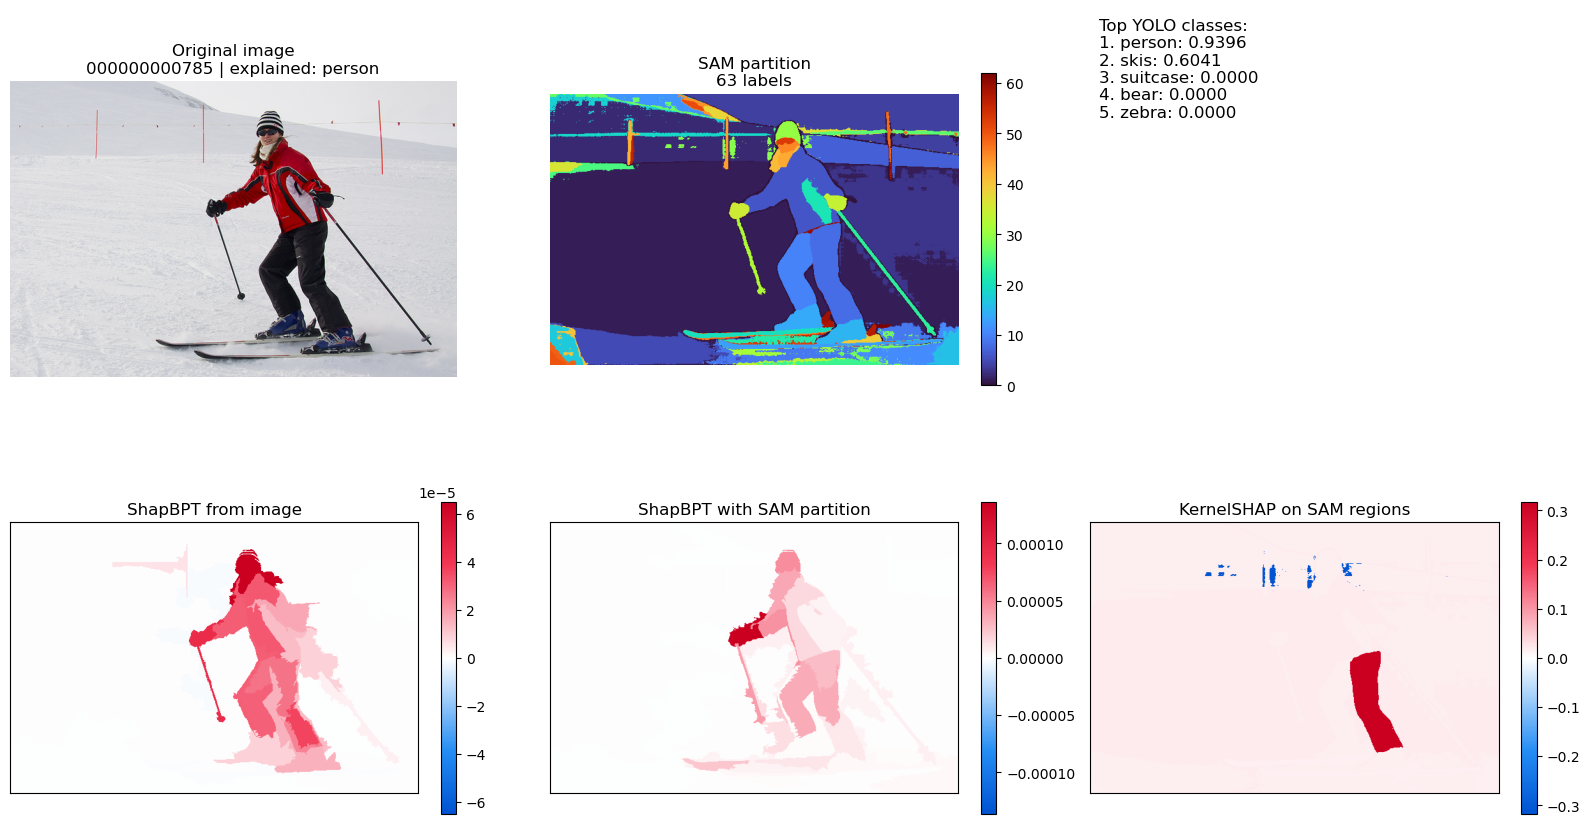

In [15]:
def show_attribution(ax, values, title, cmap):
    values = np.asarray(values)
    if values.ndim == 3:
        values_2d = values[0]
    elif values.ndim == 2:
        values_2d = values
    else:
        raise ValueError(f"Expected attribution shape (H, W) or (1, H, W), got {values.shape}")
    _, max_val = utx.scale_shap_values(values_2d, robust_percentile=99.5)
    im = ax.imshow(values_2d, cmap=cmap, vmin=-max_val, vmax=max_val)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.035)


shapley_cmap = utx.get_shapley_values_colormap()
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

axes[0].imshow(image_to_explain)
axes[0].set_title(f"Original image\n{IMAGE_ID} | explained: {fixed_category}")
axes[0].axis("off")

im = axes[1].imshow(partition_capped_sam, cmap="turbo")
axes[1].set_title(f"SAM partition\n{len(np.unique(partition_capped_sam))} labels")
axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=0.035)

axes[2].text(
    0.02,
    0.98,
    "Top YOLO classes:\n" + "\n".join([f"{i+1}. {name}: {prob:.4f}" for i, (_, name, prob) in enumerate(top_k)]),
    ha="left",
    va="top",
    fontsize=12,
)
axes[2].axis("off")

show_attribution(axes[3], shap_values_bpt_image, "ShapBPT from image", shapley_cmap)
show_attribution(axes[4], shap_values_bpt_sam, "ShapBPT with SAM partition", shapley_cmap)
show_attribution(axes[5], shap_values_kernel_sam, "KernelSHAP on SAM regions", shapley_cmap)

plt.tight_layout()
plt.show()


## Notes

- `KernelSHAP on SAM regions` treats every SAM label as a binary feature: present means the region comes from the original image; absent means it is replaced by the selected background.
- This is not pixel-level KernelSHAP. It is region-level KernelSHAP, so the feature count is the number of SAM labels after capping/sanitizing.
- If this notebook works well, the next step is to move `kernel_shap_sam_regions` into `utils_xai.py` or the full runner and save it as another method, for example `sam_kernelshap`.
